In [101]:
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
from sklearn.cluster import KMeans  # noqa: E402
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score,  # noqa: E402
                             davies_bouldin_score, silhouette_samples,
                             silhouette_score)

from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.compose import ColumnTransformer

from IPython.display import display

from nutriscope.classification import KEY_NUTRIENTS
from nutriscope.options import RANDOM_SEED as SEED
from nutriscope.figures import figure
from kneed import KneeLocator


pd.set_option("display.precision", 3)

In [102]:
df = pd.read_parquet("../data-nutriscope/nutriscope_ml_sample.parquet")

In [103]:
df_grouped = df.groupby("pnns_groups_1")

In [104]:
PNNS_TARGET = "Beverages"
Z = df_grouped.get_group(PNNS_TARGET)[KEY_NUTRIENTS]

In [105]:
preprocessor = ColumnTransformer([
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), KEY_NUTRIENTS)
])

In [106]:
lines = []
labels = {}
for k in range(2, 13):
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("kmean", KMeans(n_clusters=k, n_init=10, random_state=SEED))
    ])
    pipeline.fit(Z)
    km = pipeline.named_steps["kmean"]
    labels[k] = km.labels_
    lines.append({
        "k": k,
        "inertie": int(km.inertia_),
        "silhouette": round(float(silhouette_score(Z, km.labels_,
                                                    sample_size=10000,
                                                    random_state=SEED)), 4),
        "davies_bouldin": round(float(davies_bouldin_score(Z, km.labels_)), 3),
        "calinski": int(calinski_harabasz_score(Z, km.labels_)),
        "plus petit groupe": int(np.bincount(km.labels_).min()),
    })
bal = pd.DataFrame(lines).set_index("k")
bal.insert(1, "gain %", (100 * (bal["inertie"].shift(1) - bal["inertie"])
                            / bal["inertie"].shift(1)).round(1))
aff = bal.copy()
aff["inertie"] = aff["inertie"].map(lambda v: f"{v}")
aff["gain %"] = aff["gain %"].map(lambda v: "" if pd.isna(v) else f"{v:.1f}")
aff["silhouette"] = aff["silhouette"].map(lambda v: f"{v:.4f}")
display(aff)

,inertie,gain %,silhouette,davies_bouldin,calinski,plus petit groupe
k,,,,,,
2,9918,,0.8692,0.497,5263,111
3,7229,27.1,0.8421,1.545,2549,55
4,5583,22.8,0.0613,1.955,1737,5
5,4074,27.0,0.0574,2.220,1338,5
6,3402,16.5,0.4184,1.806,1586,5
7,3005,11.7,0.4233,1.286,1922,5
8,2615,13.0,0.4237,2.892,1688,2
9,2288,12.5,0.2710,2.801,1476,2
10,2030,11.3,0.3270,2.661,1399,2


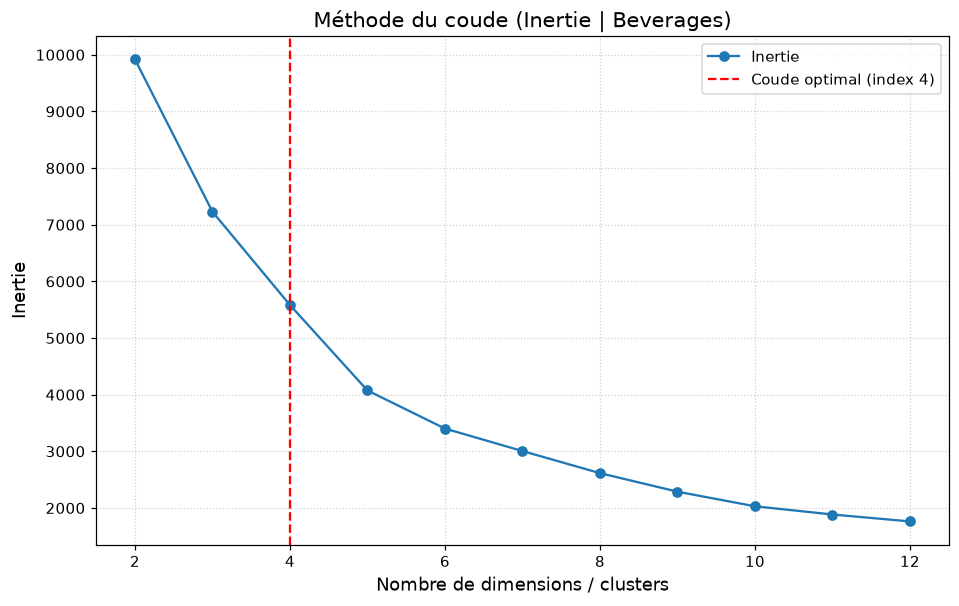

WindowsPath('C:/Users/Administrateur/Documents/Cours/NutriScope - Projet/Nutriscope_team_delegue/notebooks/figures/coude-inertie.png')

In [107]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(bal["inertie"], marker="o", label="Inertie")

# x = nombre de clusters, y = bal["inertie"]
kneedle = KneeLocator(range(1, len(bal["inertie"]) + 1), bal["inertie"], 
                      curve="convex", direction="decreasing")

optimal_k = kneedle.elbow

y_val = bal["inertie"].iloc[optimal_k]
ax.axvline(x=optimal_k, color='red', linestyle='--', label=f'Coude optimal (index {optimal_k})')

ax.set_title(f"Méthode du coude (Inertie | {PNNS_TARGET})", fontsize=14)
ax.set_xlabel("Nombre de dimensions / clusters", fontsize=12)
ax.set_ylabel("Inertie", fontsize=12)
ax.legend()
ax.grid(True, linestyle=':', alpha=0.6)

figure(fig, "coude-inertie")

C:\Users\Administrateur\AppData\Local\Temp\ipykernel_20004\1085074303.py:12: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


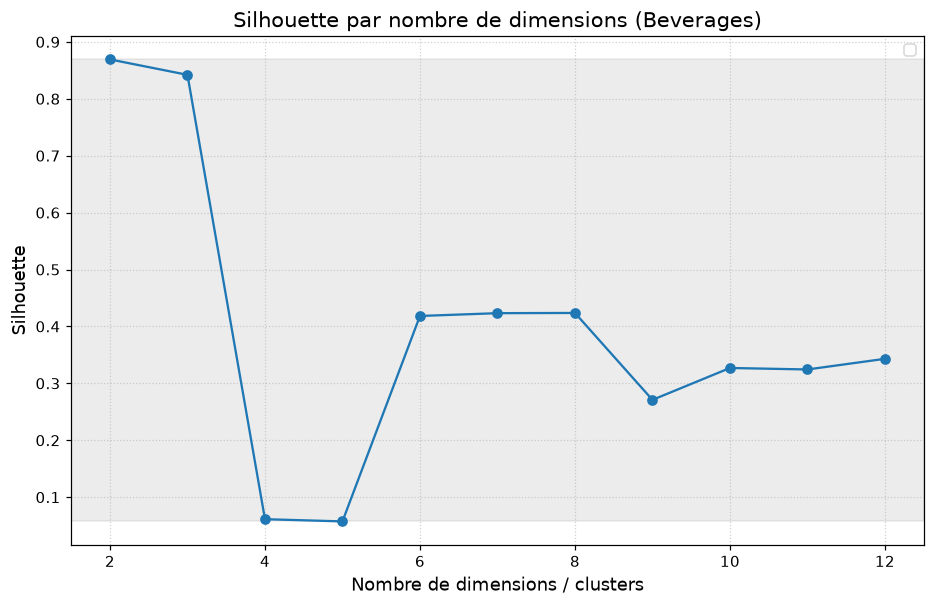

WindowsPath('C:/Users/Administrateur/Documents/Cours/NutriScope - Projet/Nutriscope_team_delegue/notebooks/figures/silhouette.png')

In [108]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(bal["silhouette"], marker="o")

limit_min = bal["silhouette"].min()
limit_max = bal["silhouette"].max()
x_window = ax.get_xlim()
ax.fill_between(x_window, limit_max, limit_min, color="grey", alpha=0.15,)
ax.set_xlim(*x_window)
ax.set_title(f"Silhouette par nombre de dimensions ({PNNS_TARGET})", fontsize=14)
ax.set_xlabel("Nombre de dimensions / clusters", fontsize=12)
ax.set_ylabel("Silhouette", fontsize=12)
ax.legend()
ax.grid(True, linestyle=':', alpha=0.6)

figure(fig, "silhouette")

- `k=2` (**Optimum statistique**) : Les métriques globales (Silhouette 0.869, Davies-Bouldin 0.497, Calinski 5263) sont au sommet.
- `k=4` (**Coude théorique**) : L'inertie baisse bien jusque là (gain cumulé de près de 50%), mais au prix d'une chute catastrophique de la Silhouette (0.061) et de micro-groupes (5 individus), ce qui rend `k=4` inexploitable en pratique.
- `k=3` (**Le juste milieu / *sweet spot***) : C'est le compromis : Un gain d'inertie majeur de *27.1%* par rapport à `k=2`. Une qualité de clustering qui reste excellente (Silhouette à *0.8421*, très proche du max). Un effectif suffisant dans le plus petit groupe (*55* produits) pour garantir la représentativité métier.

In [109]:
K_CHOSEN = 3
labeled_Z = Z.copy()
labeled_Z["label"] = labels[K_CHOSEN]
grouped_labeled_Z = labeled_Z.groupby("label")
print("\nsize\n")
display(pd.DataFrame({"n": grouped_labeled_Z.size()}))
print("\nmean\n")
display(grouped_labeled_Z.mean())
print("\nstd\n")
display(grouped_labeled_Z.std())
print("\n5 premiers\n")
for label, group in grouped_labeled_Z:
    print(label)
    display(df.iloc[group.index][["product_name", "pnns_groups_2"]].head())


size



,n
label,
0,2122
1,55
2,56



mean



,energy-kcal_100g,fat_100g,saturated-fat_100g,carbohydrates_100g,sugars_100g,proteins_100g,salt_100g
label,,,,,,,
0,32.990,0.329,0.114,6.993,6.271,0.426,0.094
1,319.255,1.918,1.451,77.502,66.988,2.001,0.248
2,270.026,18.139,12.833,19.980,9.144,8.100,0.369



std



...

,product_name,pnns_groups_2
13,Jus de fruit,Fruit juices
65,Kimura ramune yuzu citrus flavor carbonated so...,Sweetened beverages
69,Indian Tonic Water,Sweetened beverages
73,White Chocolate Mocha,Sweetened beverages
74,"Pumpkin spice latte iced espresso beverage, pu...",Sweetened beverages


1


,product_name,pnns_groups_2
300,Nesquik sirop chocolat,Sweetened beverages
1864,Sirop d'érable pur ambré,Sweetened beverages
2064,Vanilla Chai,Sweetened beverages
2313,Iced tea pêche,Sweetened beverages
2501,Capt’ain soif fraise,Sweetened beverages


2


,product_name,pnns_groups_2
60,Lait de coco,Plant-based milk substitutes
148,matcha,Teas and herbal teas and coffees
287,Caramel Latte,Plant-based milk substitutes
596,NaN,Sweetened beverages
1349,Lait de coco,Plant-based milk substitutes


0. Cluster 0 $\rightarrow$ Boissons de rafraîchissement (prêtes à boire)
1. Cluster 1 $\rightarrow$ Concentrés et sirops ultra-glucidiques
2. Cluster 2 $\rightarrow$ Boissons onctueuses & alternatives végétales